<a href="https://colab.research.google.com/github/NguyenMy18726/THHocMay/blob/main/Buoi1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

5 dòng dữ liệu đầu tiên:


,Dien_tich_m2,Gia_ban_trieu_VND
0,74.944814,1966.441513
1,144.085717,3969.768563
2,117.839273,3137.866861
3,101.839018,2793.470578
4,48.722237,1409.748731



Thống kê dữ liệu:


,Dien_tich_m2,Gia_ban_trieu_VND
count,30.00,30.00
mean,82.63,2333.03
std,33.89,790.77
min,32.47,1149.35
25%,52.50,1723.94
50%,78.39,2033.99
75%,103.10,2989.67
max,146.39,3969.77


Hệ số góc: 22.76
Hệ số chặn: 453.5
MAE: 135.47 triệu VNĐ
MSE: 30447.06
RMSE: 174.49 triệu VNĐ
R²: 0.8919


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


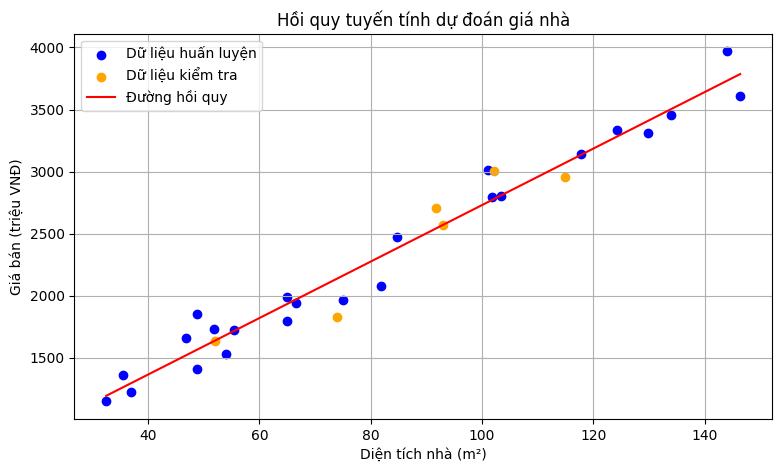

,So_luong_du_lieu,MAE,RMSE,R2
0,30,70.772,95.105,0.972
1,100,144.192,195.602,0.938
2,500,160.929,198.231,0.951
3,1000,140.871,174.534,0.959


,Do_lech_chuan_nhieu,MAE,RMSE,R2
0,0,0.000,0.000,1.000
1,100,79.749,94.026,0.990
2,300,224.285,299.769,0.909
3,600,534.710,659.967,0.553


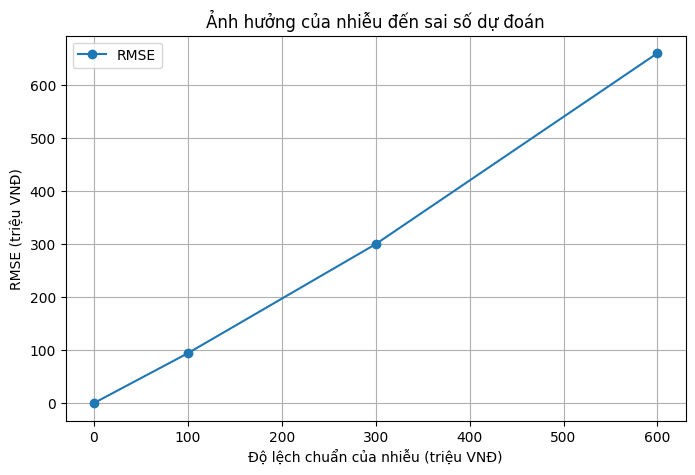

,Dien_tich,So_phong_ngu,Khoang_cach_trung_tam_km,Tuoi_nha,Gia_ban
0,86.181018,4,12.890850,10,2111.250303
1,172.607146,3,10.272374,30,3517.377070
2,139.799091,5,11.802986,27,3326.244517
3,119.798773,1,6.447153,5,2561.466996
4,53.402796,5,22.345382,40,1030.611297


,Mo_hinh,MAE,RMSE,R2
0,Hồi quy đơn biến,275.271,339.327,0.872
1,Hồi quy đa biến,121.113,149.361,0.975


Hệ số hồi quy:
Dien_tich: 19.97
So_phong_ngu: 116.53
Khoang_cach_trung_tam_km: -34.88
Tuoi_nha: -7.61
Hệ số chặn: 303.41
Thông tin căn nhà:


,Dien_tich,So_phong_ngu,Khoang_cach_trung_tam_km,Tuoi_nha
0,100,3,5,10


Giá nhà dự đoán: 2,399.28 triệu VNĐ
Tương đương: 2.399 tỷ VNĐ


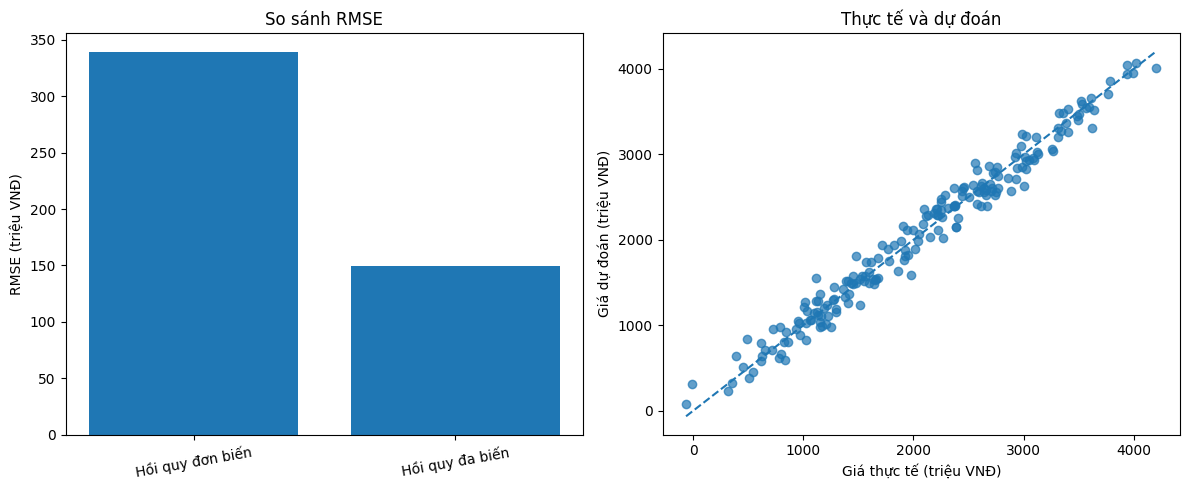

In [2]:
# -*- coding: utf-8 -*-
"""Lab_1_Hoi_Quy_Tuyen_Tinh_Du_Doan_Gia_Nha.ipynb

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/drive/1YhlATs36wveN-aH2m6eU5WmwirXtKKpV
"""

# Khai báo thư viện và tạo dữ liệu

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Đảm bảo kết quả có thể tái lập
np.random.seed(42)

# Tạo 30 căn nhà giả lập
n = 30
dien_tich = np.random.uniform(30, 150, n)

# Giá nhà giả lập: giá phụ thuộc vào diện tích và có nhiễu
gia_ban = 25 * dien_tich + 300 + np.random.normal(0, 180, n)

df = pd.DataFrame({
    "Dien_tich_m2": dien_tich,
    "Gia_ban_trieu_VND": gia_ban
})

print("5 dòng dữ liệu đầu tiên:")
display(df.head())

print("\nThống kê dữ liệu:")
display(df.describe().round(2))
#===================================================================
#Huấn luyện mô hình và đánh giá

X = df[["Dien_tich_m2"]]
y = df["Gia_ban_trieu_VND"]

# Chia 80% dữ liệu huấn luyện, 20% dữ liệu kiểm tra
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Xây dựng mô hình hồi quy tuyến tính
model = LinearRegression()
model.fit(X_train, y_train)

# Dự đoán trên tập kiểm tra
y_pred = model.predict(X_test)

# Các chỉ số đánh giá
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Hệ số góc:", round(model.coef_[0], 2))
print("Hệ số chặn:", round(model.intercept_, 2))
print("MAE:", round(mae, 2), "triệu VNĐ")
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2), "triệu VNĐ")
print("R²:", round(r2, 4))

#===================================================================
#Vẽ biểu đồ đường hồi quy
plt.figure(figsize=(9, 5))

plt.scatter(
    X_train["Dien_tich_m2"], y_train,
    color="blue", label="Dữ liệu huấn luyện"
)
plt.scatter(
    X_test["Dien_tich_m2"], y_test,
    color="orange", label="Dữ liệu kiểm tra"
)

x_line = np.linspace(
    df["Dien_tich_m2"].min(),
    df["Dien_tich_m2"].max(),
    100
).reshape(-1, 1)

plt.plot(
    x_line,
    model.predict(x_line),
    color="red", label="Đường hồi quy"
)

plt.xlabel("Diện tích nhà (m²)")
plt.ylabel("Giá bán (triệu VNĐ)")
plt.title("Hồi quy tuyến tính dự đoán giá nhà")
plt.legend()
plt.grid(True)
plt.show()

#==========================================================
#So sánh các tập dữ liệu có kích thước khác nhau
def tao_du_lieu(n, muc_nhieu=180):
    dien_tich = np.random.uniform(30, 150, n)
    gia_ban = (
        25 * dien_tich
        + 300
        + np.random.normal(0, muc_nhieu, n)
    )

    return pd.DataFrame({
        "Dien_tich": dien_tich,
        "Gia_ban": gia_ban
    })


def danh_gia_mo_hinh(data):
    X = data[["Dien_tich"]]
    y = data["Gia_ban"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    return {
        "So_luong_du_lieu": len(data),
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    }


ket_qua = []

for so_luong in [30, 100, 500, 1000]:
    data = tao_du_lieu(so_luong, muc_nhieu=180)
    ket_qua.append(danh_gia_mo_hinh(data))

bang_ket_qua = pd.DataFrame(ket_qua)
display(bang_ket_qua.round(3))
#==========================================================
#Thử nghiệm với nhiều mức nhiễu

ket_qua_nhieu = []

for muc_nhieu in [0, 100, 300, 600]:
    data = tao_du_lieu(500, muc_nhieu=muc_nhieu)
    kq = danh_gia_mo_hinh(data)

    kq["Do_lech_chuan_nhieu"] = muc_nhieu
    ket_qua_nhieu.append(kq)

bang_nhieu = pd.DataFrame(ket_qua_nhieu)
display(
    bang_nhieu[
        ["Do_lech_chuan_nhieu", "MAE", "RMSE", "R2"]
    ].round(3)
)

plt.figure(figsize=(8, 5))
plt.plot(
    bang_nhieu["Do_lech_chuan_nhieu"],
    bang_nhieu["RMSE"],
    marker="o",
    label="RMSE"
)
plt.xlabel("Độ lệch chuẩn của nhiễu (triệu VNĐ)")
plt.ylabel("RMSE (triệu VNĐ)")
plt.title("Ảnh hưởng của nhiễu đến sai số dự đoán")
plt.grid(True)
plt.legend()
plt.show()

#======================================================
#Tạo dữ liệu có nhiều biến đầu vào

np.random.seed(42)

n = 1000

dien_tich = np.random.uniform(30, 180, n)
so_phong_ngu = np.random.randint(1, 6, n)
khoang_cach = np.random.uniform(1, 25, n)
tuoi_nha = np.random.randint(0, 41, n)

# Công thức giả lập giá nhà, đơn vị triệu VNĐ
gia_ban = (
    20 * dien_tich
    + 120 * so_phong_ngu
    - 35 * khoang_cach
    - 8 * tuoi_nha
    + 300
    + np.random.normal(0, 150, n)
)

df_nhieu_bien = pd.DataFrame({
    "Dien_tich": dien_tich,
    "So_phong_ngu": so_phong_ngu,
    "Khoang_cach_trung_tam_km": khoang_cach,
    "Tuoi_nha": tuoi_nha,
    "Gia_ban": gia_ban
})

display(df_nhieu_bien.head())
#================================================
#Huấn luyện và so sánh 2 mô hình

# Dùng cùng một tập dữ liệu và cùng cách chia train/test
train_idx, test_idx = train_test_split(
    df_nhieu_bien.index,
    test_size=0.2,
    random_state=42
)

y_train = df_nhieu_bien.loc[train_idx, "Gia_ban"]
y_test = df_nhieu_bien.loc[test_idx, "Gia_ban"]

# Mô hình 1: chỉ dùng diện tích
X_don = df_nhieu_bien[["Dien_tich"]]
model_don = LinearRegression()
model_don.fit(X_don.loc[train_idx], y_train)
pred_don = model_don.predict(X_don.loc[test_idx])

# Mô hình 2: dùng tất cả các biến đầu vào
cac_bien = [
    "Dien_tich",
    "So_phong_ngu",
    "Khoang_cach_trung_tam_km",
    "Tuoi_nha"
]

X_da_bien = df_nhieu_bien[cac_bien]

model_da_bien = LinearRegression()
model_da_bien.fit(X_da_bien.loc[train_idx], y_train)
pred_da_bien = model_da_bien.predict(X_da_bien.loc[test_idx])

# Bảng so sánh
so_sanh = pd.DataFrame({
    "Mo_hinh": [
        "Hồi quy đơn biến",
        "Hồi quy đa biến"
    ],
    "MAE": [
        mean_absolute_error(y_test, pred_don),
        mean_absolute_error(y_test, pred_da_bien)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, pred_don)),
        np.sqrt(mean_squared_error(y_test, pred_da_bien))
    ],
    "R2": [
        r2_score(y_test, pred_don),
        r2_score(y_test, pred_da_bien)
    ]
})

display(so_sanh.round(3))

# Xem các hệ số của mô hình đa biến
print("Hệ số hồi quy:")
for ten_bien, he_so in zip(cac_bien, model_da_bien.coef_):
    print(f"{ten_bien}: {he_so:.2f}")

print("Hệ số chặn:", round(model_da_bien.intercept_, 2))
#=============================================================
#Thử dự đoán giá của 1 căn nhà mới

nha_moi = pd.DataFrame({
    "Dien_tich": [100],
    "So_phong_ngu": [3],
    "Khoang_cach_trung_tam_km": [5],
    "Tuoi_nha": [10]
})

gia_du_doan = model_da_bien.predict(nha_moi)[0]

print("Thông tin căn nhà:")
display(nha_moi)

print(f"Giá nhà dự đoán: {gia_du_doan:,.2f} triệu VNĐ")
print(f"Tương đương: {gia_du_doan / 1000:,.3f} tỷ VNĐ")
#=============================================================
#Biểu đồ so sánh kết quả

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# So sánh sai số
axes[0].bar(so_sanh["Mo_hinh"], so_sanh["RMSE"])
axes[0].set_title("So sánh RMSE")
axes[0].set_ylabel("RMSE (triệu VNĐ)")
axes[0].tick_params(axis="x", rotation=10)

# Giá thực tế so với giá dự đoán của mô hình đa biến
axes[1].scatter(y_test, pred_da_bien, alpha=0.7)

gioi_han_min = min(y_test.min(), pred_da_bien.min())
gioi_han_max = max(y_test.max(), pred_da_bien.max())

axes[1].plot(
    [gioi_han_min, gioi_han_max],
    [gioi_han_min, gioi_han_max],
    linestyle="--"
)

axes[1].set_xlabel("Giá thực tế (triệu VNĐ)")
axes[1].set_ylabel("Giá dự đoán (triệu VNĐ)")
axes[1].set_title("Thực tế và dự đoán")

plt.tight_layout()
plt.show()

5 dòng dữ liệu đầu tiên:


,BMI,Mac_benh
0,24.988963,1
1,38.817143,1
2,33.567855,1
3,30.367804,0
4,19.744447,0



Thống kê dữ liệu:


,BMI,Mac_benh
count,500.00,500.00
mean,27.97,0.54
std,7.17,0.50
min,16.12,0.00
25%,21.79,0.00
50%,28.32,1.00
75%,34.15,1.00
max,39.83,1.00



Số lượng từng nhãn:
Mac_benh
0    228
1    272
Name: count, dtype: int64


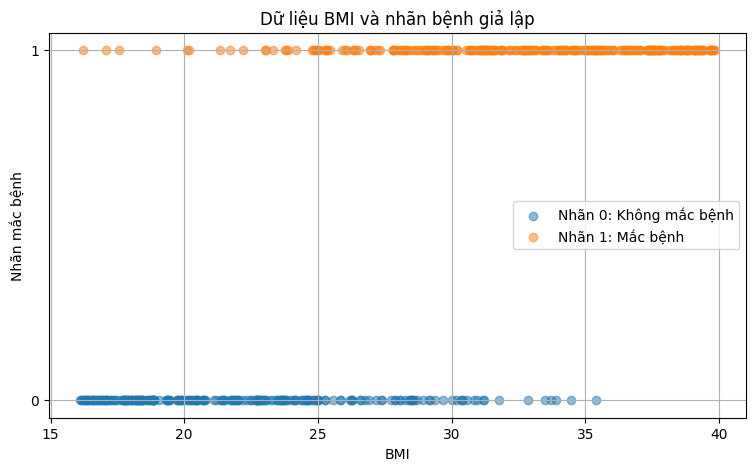

Hệ số hồi quy: 0.3553634372979319
Hệ số chặn: -9.522191875523129
Số mẫu huấn luyện: 400
Số mẫu kiểm tra: 100


,BMI,Nhan_thuc_te,Xac_suat_mac_benh,Nhan_du_doan
0,30.554,1,0.792,1
1,36.472,1,0.969,1
2,21.694,1,0.140,0
3,17.665,0,0.038,0
4,18.786,0,0.055,0
5,32.703,1,0.891,1
6,23.545,0,0.240,0
7,28.036,1,0.608,1
8,34.652,1,0.942,1
9,37.360,1,0.977,1


Accuracy: 0.9100
Accuracy (%): 91.00%

Ma trận nhầm lẫn:
[[41  5]
 [ 4 50]]


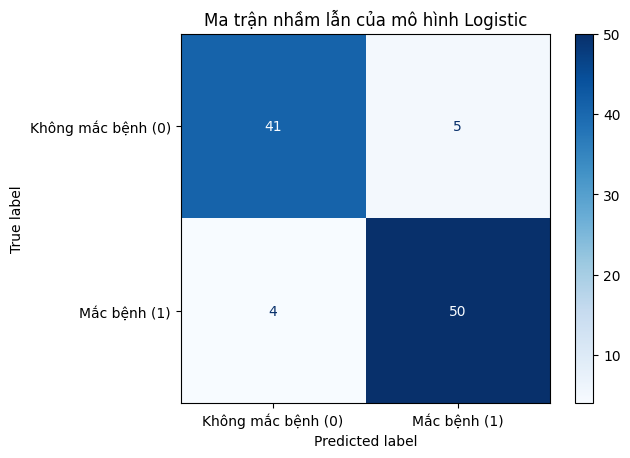


Báo cáo phân loại:
                precision    recall  f1-score   support

Không mắc bệnh       0.91      0.89      0.90        46
      Mắc bệnh       0.91      0.93      0.92        54

      accuracy                           0.91       100
     macro avg       0.91      0.91      0.91       100
  weighted avg       0.91      0.91      0.91       100



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


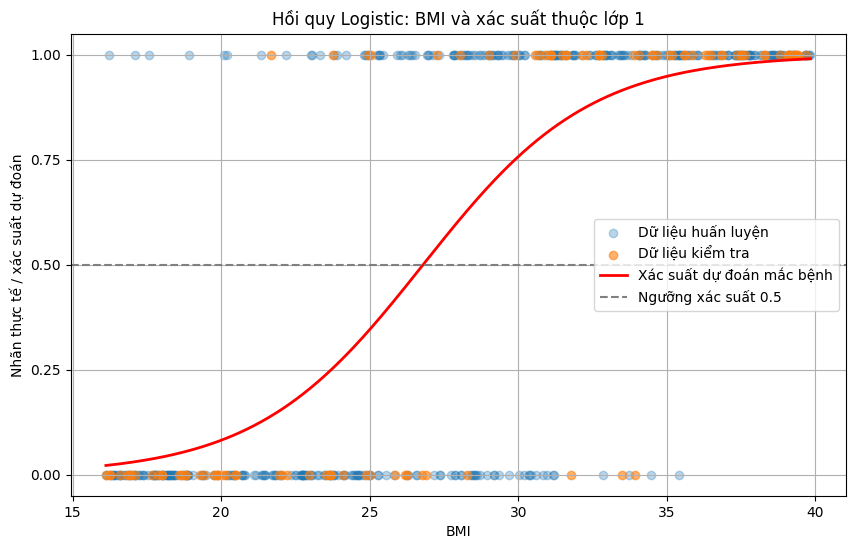

In [3]:
# -*- coding: utf-8 -*-
"""Bai_2_Du_Doan_Benh_Bang_hoi_Quy_Logistic.ipynb

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/drive/1PlXduqK6n-4syowYyxZy4SiNFZeouInO
"""

#Khai báo thư viện và tạo dữ liệu giả lập

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Cố định số ngẫu nhiên để dễ tái lập kết quả
np.random.seed(42)

# Tạo 500 bệnh nhân giả lập
n = 500

# BMI nằm trong khoảng từ 16 đến 40
bmi = np.random.uniform(16, 40, n)

# Tính xác suất mắc bệnh giả lập từ BMI
xac_suat = 1 / (1 + np.exp(-(bmi - 27) / 3))

# Sinh nhãn 0 hoặc 1 dựa trên xác suất
mac_benh = np.random.binomial(1, xac_suat)

# Tạo bảng dữ liệu
df = pd.DataFrame({
    "BMI": bmi,
    "Mac_benh": mac_benh
})

print("5 dòng dữ liệu đầu tiên:")
display(df.head())

print("\nThống kê dữ liệu:")
display(df.describe().round(2))

print("\nSố lượng từng nhãn:")
print(df["Mac_benh"].value_counts().sort_index())
#=======================================================
#Trực quan hóa dữ liệu

plt.figure(figsize=(9, 5))

plt.scatter(
    df.loc[df["Mac_benh"] == 0, "BMI"],
    df.loc[df["Mac_benh"] == 0, "Mac_benh"],
    alpha=0.5,
    label="Nhãn 0: Không mắc bệnh"
)

plt.scatter(
    df.loc[df["Mac_benh"] == 1, "BMI"],
    df.loc[df["Mac_benh"] == 1, "Mac_benh"],
    alpha=0.5,
    label="Nhãn 1: Mắc bệnh"
)

plt.xlabel("BMI")
plt.ylabel("Nhãn mắc bệnh")
plt.title("Dữ liệu BMI và nhãn bệnh giả lập")
plt.yticks([0, 1])
plt.legend()
plt.grid(True)
plt.show()
#=====================================================
#Chia dữ liệu và huấn luyện hồi quy logistic

# X: biến đầu vào
X = df[["BMI"]]

# y: nhãn cần dự đoán
y = df["Mac_benh"]

# Chia dữ liệu thành 80% huấn luyện và 20% kiểm tra
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Khởi tạo mô hình
model = LogisticRegression()

# Huấn luyện mô hình
model.fit(X_train, y_train)

print("Hệ số hồi quy:", model.coef_[0][0])
print("Hệ số chặn:", model.intercept_[0])
print("Số mẫu huấn luyện:", len(X_train))
print("Số mẫu kiểm tra:", len(X_test))
#=======================================================
#Dự đoán xác suất và nhãn mắc bệnh

# Dự đoán xác suất của từng lớp
y_prob = model.predict_proba(X_test)[:, 1]

# Dự đoán nhãn 0 hoặc 1
y_pred = model.predict(X_test)

# Tạo bảng so sánh
bang_du_doan = pd.DataFrame({
    "BMI": X_test["BMI"].values,
    "Nhan_thuc_te": y_test.values,
    "Xac_suat_mac_benh": y_prob,
    "Nhan_du_doan": y_pred
})

display(bang_du_doan.head(10).round(3))
#=================================================
#Đánh giá bằng accuracy và ma trận nhầm lẫn

# Tính độ chính xác
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy (%): {accuracy * 100:.2f}%")

# Tạo ma trận nhầm lẫn
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("\nMa trận nhầm lẫn:")
print(cm)

# Hiển thị ma trận dưới dạng biểu đồ
display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Không mắc bệnh (0)", "Mắc bệnh (1)"]
)

display_cm.plot(cmap="Blues", values_format="d")
plt.title("Ma trận nhầm lẫn của mô hình Logistic")
plt.show()

# Báo cáo các chỉ số phân loại
print("\nBáo cáo phân loại:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Không mắc bệnh", "Mắc bệnh"],
    zero_division=0
))
#======================================================
#Trực quan hóa đường hồi quy logistic

# Tạo dải BMI liên tục để vẽ đường xác suất
bmi_line = np.linspace(
    df["BMI"].min(),
    df["BMI"].max(),
    300
).reshape(-1, 1)

# Tính xác suất thuộc lớp 1
prob_line = model.predict_proba(bmi_line)[:, 1]

plt.figure(figsize=(10, 6))

# Các điểm dữ liệu thực tế
plt.scatter(
    X_train["BMI"],
    y_train,
    alpha=0.3,
    label="Dữ liệu huấn luyện"
)

plt.scatter(
    X_test["BMI"],
    y_test,
    alpha=0.6,
    label="Dữ liệu kiểm tra"
)

# Đường xác suất Logistic
plt.plot(
    bmi_line.ravel(),
    prob_line,
    color="red",
    linewidth=2,
    label="Xác suất dự đoán mắc bệnh"
)

# Ngưỡng phân loại mặc định
plt.axhline(
    0.5,
    color="gray",
    linestyle="--",
    label="Ngưỡng xác suất 0.5"
)

plt.xlabel("BMI")
plt.ylabel("Nhãn thực tế / xác suất dự đoán")
plt.title("Hồi quy Logistic: BMI và xác suất thuộc lớp 1")
plt.yticks([0, 0.25, 0.5, 0.75, 1])
plt.ylim(-0.05, 1.05)
plt.legend()
plt.grid(True)
plt.show()

===== 1. THONG TIN DU LIEU =====
So dong, so cot: (442, 11)

5 dong du lieu dau tien:
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  Chi_so_tien_trien_benh  
0 -0.002592  0.019907 -0.017646                   151.0  
1 -0.039493 -0.068332 -0.092204                    75.0  
2 -0.002592  0.002861 -0.025930                   141.0  
3  0.034309  0.022688 -0.009362                   206.0  
4 -0.002592 -0.031988 -0.046641                   135.0  

===== 2. THONG KE DU LIEU =====
          age     sex     bmi      bp      s1      s2      s3      s4      s5  \
c

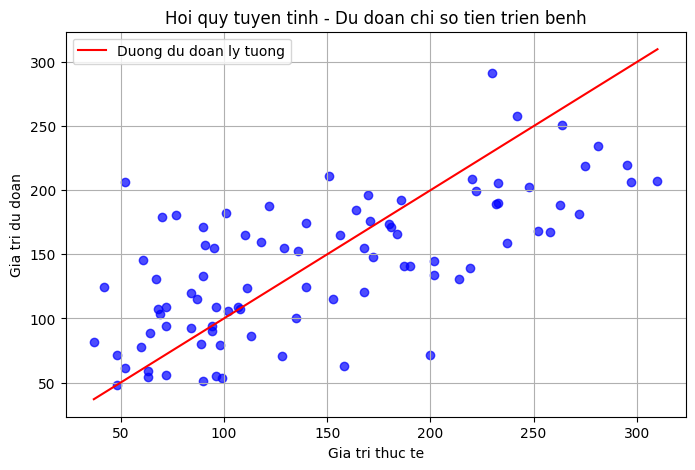

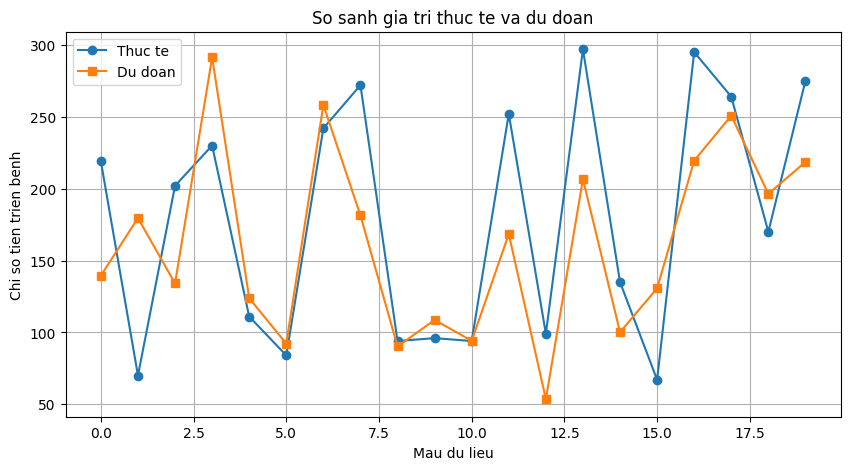


===== 6. HE SO HOI QUY =====
He so chan: 151.346
  Dac_trung    He_so
0       age   37.904
1       sex -241.964
2       bmi  542.429
3        bp  347.704
4        s1 -931.489
5        s2  518.062
6        s3  163.420
7        s4  275.318
8        s5  736.199
9        s6   48.671

===== HOAN THANH BAI 3 =====


In [4]:

# BAI 3 O LOP - HOI QUY TUYEN TINH
# Du doan chi so tien trien benh tu bo du lieu Diabetes

# 1. Import thu vien
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 2. Tai bo du lieu
diabetes = load_diabetes()
X = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
y = diabetes.target

df = X.copy()
df["Chi_so_tien_trien_benh"] = y

print("===== 1. THONG TIN DU LIEU =====")
print("So dong, so cot:", df.shape)
print("\n5 dong du lieu dau tien:")
print(df.head())

# 3. Kiem tra va thong ke du lieu
print("\n===== 2. THONG KE DU LIEU =====")
print(df.describe().round(2))

print("\nSo gia tri thieu:")
print(df.isnull().sum())

# 4. Chia du lieu
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\n===== 3. CHIA DU LIEU =====")
print("So mau huan luyen:", len(X_train))
print("So mau kiem tra:", len(X_test))

# 5. Tao va huan luyen mo hinh
model = LinearRegression()
model.fit(X_train, y_train)

# 6. Du doan
y_pred = model.predict(X_test)

print("\n===== 4. KET QUA DU DOAN =====")
ket_qua = pd.DataFrame({
    "Gia_tri_thuc_te": y_test,
    "Gia_tri_du_doan": y_pred
})
print(ket_qua.head(10).round(2))

# 7. Danh gia mo hinh
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n===== 5. DANH GIA MO HINH =====")
print("MAE:", round(mae, 3))
print("MSE:", round(mse, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))

# 8. Bieu do gia tri thuc te va du doan
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, color="blue", alpha=0.7)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    label="Duong du doan ly tuong"
)

plt.title("Hoi quy tuyen tinh - Du doan chi so tien trien benh")
plt.xlabel("Gia tri thuc te")
plt.ylabel("Gia tri du doan")
plt.legend()
plt.grid(True)
plt.show()

# 9. Bieu do so sanh 20 mau
plt.figure(figsize=(10, 5))
plt.plot(y_test[:20], marker="o", label="Thuc te")
plt.plot(y_pred[:20], marker="s", label="Du doan")

plt.title("So sanh gia tri thuc te va du doan")
plt.xlabel("Mau du lieu")
plt.ylabel("Chi so tien trien benh")
plt.legend()
plt.grid(True)
plt.show()

# 10. Hien thi he so hoi quy
print("\n===== 6. HE SO HOI QUY =====")
print("He so chan:", round(model.intercept_, 3))

he_so = pd.DataFrame({
    "Dac_trung": X.columns,
    "He_so": model.coef_
})
print(he_so.round(3))

print("\n===== HOAN THANH BAI 3 =====")
